# Structure Learning

This notebook covers the **structure** part of our Bayesian network (report Section 3). The question is: *which graph should the network use, and does the data back up the graph we proposed?*

| § | What | Why |
|---|---|---|
| 1 | Pairwise mutual information | Model-free view of which variables are related at all |
| 2 | Hand-designed DAG from the proposal | Our prior beliefs, written down before any learning |
| 3 | Hill Climb + BIC, plus variants (in-degree caps, warm start, popularity as a sink) | The structure-learning method from the proposal |
| 4 | Score sensitivity: BIC vs. AIC, K2 and BDeu | How much the learned graph depends on the score's complexity penalty |
| 5 | Other algorithms: PC, GES, Chow-Liu tree, Naive Bayes, TAN | Constraint-based and classifier-style alternatives |
| 6 | Sweep over how many parents popularity gets | How large popularity's CPT should be |
| 7 | **Predictive comparison with 5-fold CV** | BIC is the score Hill Climb optimizes, so we also judge structures by how well they predict popularity |
| 8 | Bootstrap edge stability and consensus DAG | Which edges are reliable, and which are artifacts of this particular sample |
| 9 | Hand DAG vs. learned DAG, compared up to Markov equivalence | Separates real disagreements from edge directions that data cannot identify |
| 10 | Export to `models/structures.json` | So every downstream stage uses identical graphs |

Everything here uses only `train.csv`; model selection relies on cross-validation within it. `test.csv` is read for one purpose only: listing every state a variable can take, so that all CPTs have the same shape. No metric is ever computed on it. Test-set evaluation belongs to the evaluation stage.

In [1]:
import os, json, itertools, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.special import logsumexp
from sklearn.model_selection import KFold
from sklearn.metrics import normalized_mutual_info_score

warnings.filterwarnings("ignore")  # pgmpy deprecation chatter
from pgmpy.base import DAG
from pgmpy.estimators import HillClimbSearch, TreeSearch, PC, GES, BIC, AIC, K2, BDeu
from pgmpy.causal_discovery import ExpertKnowledge

SEED = 150
FIG_DIR = Path("figures/structure"); FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

# Colour roles (validated categorical palette, slots 1-2): blue = ordinary marks, orange = popularity / hand-designed
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#a3a29c", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.titlesize": 10, "axes.labelsize": 9, "font.size": 9})

if os.environ.get("PYTHONHASHSEED") != "0":
    print("WARNING: PYTHONHASHSEED is not 0. pgmpy breaks score ties using set-iteration order, so the learned "
          "graphs may differ slightly from the frozen models/structures.json. To reproduce exactly, start "
          "Jupyter with `PYTHONHASHSEED=0 jupyter lab`.")

## Data

We drop the identifier columns (`name`, `artist`) and treat every remaining column as a discrete variable. The state space of each variable comes from the full processed dataset, so a state that appears only in the test split still gets a slot in the CPTs.

In [2]:
from bn_structures import load_split   # shared loader, so every stage sees identical data
train, test = load_split()
full = pd.concat([train, test])        # used ONLY to enumerate state names; no metric touches test

VARS = list(train.columns)
STATES = {v: sorted(full[v].unique()) for v in VARS}
CARD = {v: len(s) for v, s in STATES.items()}
FEATURES = [v for v in VARS if v != "popularity"]
POP_STATES = STATES["popularity"]
MAJORITY = train["popularity"].mode()[0]

print(f"train: {len(train)} rows")
print(f"majority popularity class in train: {MAJORITY} ({(train.popularity == MAJORITY).mean():.1%} of train)")
pd.Series(CARD, name="number of states").to_frame().T

train: 3571 rows
majority popularity class in train: (40.0, 60.0] (34.4% of train)


,mode,key,popularity,energy,tempo,valence,danceability,acousticness,decade,duration
number of states,2,12,5,5,4,5,5,5,5,5


## Helper functions

**Scoring a graph.**
* `n_params(g)` counts free CPT parameters: $\sum_i (r_i-1)\prod_{j\in Pa(i)} r_j$.
* `bic(g)` is BIC on train: log-likelihood $-\ \frac{\log N}{2}\times$ number of parameters. Higher is better.
* Every scorer, learner and CPT fit uses the **same state space** (`STATES`, built from train + test). A cross-validation fold that happens to lack a rare state still gets CPTs of the same size, so the parameter counts and BIC penalties always describe the same model.

**Fitting a graph (`SmoothedBN`).** CPTs are estimated from counts with add-one (Laplace) smoothing, $\hat P(x\mid u) = \frac{N_{xu}+1}{N_u + r}$, which is a Dirichlet prior with pseudocount 1. This fixed fit is used only to compare *structures*. The proper sweep over pseudocounts belongs to parameter learning (Ethan).

**Predicting popularity.** Popularity is conditionally independent of every other variable given its Markov blanket, so
$$P(\text{pop}=c \mid \text{everything else}) \propto P(c \mid Pa(\text{pop}))\prod_{k \in Ch(\text{pop})} P(x_k \mid Pa(x_k))\Big|_{\text{pop}=c}.$$
This computes the exact posterior with no general-purpose inference engine, so we can score dozens of graphs, times folds, quickly. The metrics are:
* **popularity log-loss**: the average of $-\log P(\text{true class}\mid\text{rest})$. Lower is better, and it rewards calibrated probabilities as well as correct guesses.
* **accuracy** of the most probable class.

In [3]:
def scorer(kind, data, **kw):
    # pgmpy structure score that always uses the full state space
    return {"bic": BIC, "aic": AIC, "k2": K2, "bdeu": BDeu}[kind](data, state_names=STATES, **kw)

bic_scorer = scorer("bic", train)

def make_dag(edges):
    g = DAG(); g.add_nodes_from(VARS); g.add_edges_from(edges); return g

def n_params(g):
    return int(sum((CARD[v] - 1) * np.prod([CARD[p] for p in g.get_parents(v)] or [1]) for v in VARS))

def bic(g, scorer=None):
    return float((scorer or bic_scorer).score(g))

class SmoothedBN:
    # Discrete BN with add-alpha smoothed CPTs, vectorised over DataFrame rows.
    def __init__(self, g, data, alpha=1.0):
        self.g, self.alpha = g, alpha
        self.pa = {v: sorted(g.get_parents(v)) for v in VARS}
        self.ch = sorted(g.get_children("popularity"))
        self.joint, self.pacount = {}, {}
        for v in VARS:
            pa = self.pa[v]
            self.joint[v] = Counter(map(tuple, data[pa + [v]].to_numpy()))
            self.pacount[v] = Counter(map(tuple, data[pa].to_numpy())) if pa else Counter({(): len(data)})

    def node_logp(self, v, df):
        pa, a, r = self.pa[v], self.alpha, CARD[v]
        J, P = self.joint[v], self.pacount[v]
        keys = map(tuple, df[pa + [v]].to_numpy())
        pkeys = map(tuple, df[pa].to_numpy()) if pa else [()] * len(df)
        return np.log(np.array([(J[k] + a) / (P[p] + a * r) for k, p in zip(keys, pkeys)]))

    def loglik(self, df):
        return sum(self.node_logp(v, df) for v in VARS)

    def popularity_log_posterior(self, df):
        # (n_rows, n_classes) matrix of log P(pop = c | all other variables)
        scores = []
        for c in POP_STATES:
            dc = df.assign(popularity=c)
            scores.append(sum(self.node_logp(v, dc) for v in ["popularity"] + self.ch))
        S = np.column_stack(scores)
        return S - logsumexp(S, axis=1, keepdims=True)

def evaluate(g, fit_df, eval_df):
    m = SmoothedBN(g, fit_df)
    lp = m.popularity_log_posterior(eval_df)
    y = eval_df["popularity"].map({c: i for i, c in enumerate(POP_STATES)}).to_numpy()
    return {"pop log-loss": -lp[np.arange(len(y)), y].mean(),
            "pop accuracy": (lp.argmax(1) == y).mean(),
            "joint LL / song": m.loglik(eval_df).mean()}

def skeleton(g):
    return {frozenset(e) for e in g.edges()}

def shd(g1, g2):
    # structural Hamming distance: missing + extra + reversed edges
    s1, s2 = skeleton(g1), skeleton(g2)
    return len(s1 ^ s2) + sum(1 for (a, b) in g1.edges() if (b, a) in g2.edges())

def vstructures(g):
    out = set()
    for c in g.nodes:
        for a, b in itertools.combinations(sorted(g.get_parents(c)), 2):
            if not g.has_edge(a, b) and not g.has_edge(b, a):
                out.add((a, c, b))
    return out

def popularity_mb(g):
    ch = set(g.get_children("popularity"))
    mb = set(g.get_parents("popularity")) | ch
    for c in ch: mb |= set(g.get_parents(c))
    mb.discard("popularity"); return sorted(mb)

## Drawing DAGs

Every graph uses the same fixed node layout so the figures can be compared side by side. Popularity and the edges touching it are drawn in orange.

In [4]:
POS = {
    "decade":   (0.0, 3.0), "mode": (2.0, 3.0), "key": (4.0, 3.0),
    "duration": (-1.0, 2.0), "acousticness": (1.0, 2.0), "tempo": (3.0, 2.0),
    "energy":   (1.0, 1.0), "valence": (3.0, 1.0),
    "danceability": (2.0, 0.0), "popularity": (0.0, 0.0),
}
assert set(POS) == set(VARS)
LABEL = {v: {"acousticness": "acoustic-\nness", "danceability": "dance-\nability"}.get(v, v) for v in VARS}

def draw_dag(g, title, ax=None, path=None, widths=None):
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(6.2, 4.6))
    G = nx.DiGraph(); G.add_nodes_from(VARS); G.add_edges_from(g.edges())
    nx.draw_networkx_nodes(G, POS, ax=ax, node_size=1700, edgecolors=MUTED, linewidths=1,
                           node_color=[ORANGE if n == "popularity" else "#dce8f7" for n in G.nodes])
    nx.draw_networkx_labels(G, POS, labels=LABEL, ax=ax, font_size=7.5, font_color=INK)
    for e in G.edges:
        w = 1.4 if widths is None else 0.6 + 3.0 * widths.get(e, 0)
        nx.draw_networkx_edges(G, POS, edgelist=[e], ax=ax, arrows=True, arrowsize=14, node_size=1700,
                               width=w * (1.5 if "popularity" in e else 1),
                               edge_color=ORANGE if "popularity" in e else MUTED,
                               connectionstyle="arc3,rad=0.08")
    ax.set_title(title); ax.axis("off"); ax.margins(0.12)
    if own:
        plt.tight_layout()
        if path: plt.savefig(path, dpi=200, bbox_inches="tight")
        plt.show()

def draw_grid(named, path, ncols=2):
    n = len(named); nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 4.6 * nrows))
    for ax in np.ravel(axes)[n:]: ax.axis("off")
    for ax, (name, g) in zip(np.ravel(axes), named.items()):
        draw_dag(g, f"{name}  (BIC {bic(g):,.0f})", ax=ax)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

## 1. Pairwise mutual information

Before fitting any graph, we measure how strongly each pair of variables is related, using normalized mutual information (0 means independent, 1 means each determines the other). This is model-free: it shows which edges are even possible candidates, and how weakly popularity relates to the audio features.

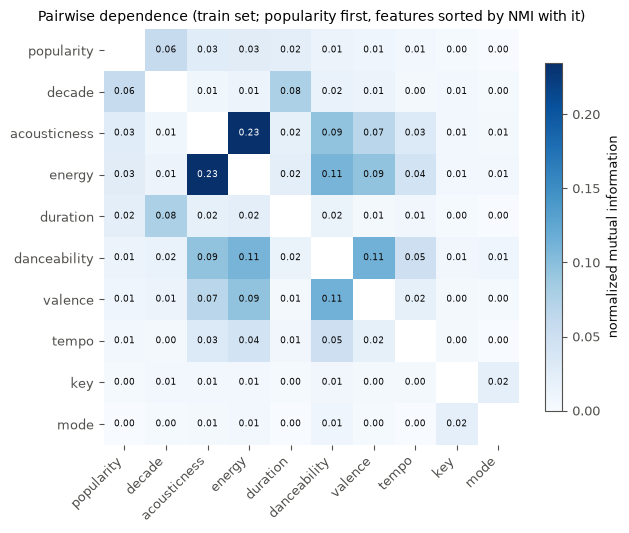

,decade,acousticness,energy,duration,danceability,valence,tempo,key,mode
NMI with popularity,0.0574,0.0268,0.0257,0.023,0.0133,0.0094,0.0063,0.0034,0.0008


In [5]:
nmi = pd.DataFrame([[normalized_mutual_info_score(train[a], train[b]) if a != b else np.nan for b in VARS] for a in VARS],
                   index=VARS, columns=VARS)
order = ["popularity"] + sorted(FEATURES, key=lambda f: -nmi.loc["popularity", f])
nmi = nmi.loc[order, order]
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(nmi, cmap="Blues", vmin=0)
ax.set_xticks(range(len(order)), order, rotation=45, ha="right"); ax.set_yticks(range(len(order)), order)
vmax = np.nanmax(nmi.values)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j:
            v = nmi.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if v > 0.6 * vmax else INK)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="normalized mutual information")
ax.set_title("Pairwise dependence (train set; popularity first, features sorted by NMI with it)")
plt.tight_layout(); plt.savefig(FIG_DIR / "mutual_information.png", dpi=200, bbox_inches="tight"); plt.show()
nmi.loc["popularity"].drop("popularity").sort_values(ascending=False).round(4).to_frame("NMI with popularity").T

## 2. Hand-designed DAG (from the proposal)

The proposal suggested edges like energy → loudness and energy → valence (positivity), and a small, capped set of parents for popularity. `loudness` was dropped during preprocessing because it is nearly redundant with `energy`, so energy → loudness is gone. Every edge below is a prior belief, written down **before** looking at any structure-learning output:

| Edge | Reason |
|---|---|
| acousticness → energy | acoustic recordings tend to be quieter and less intense |
| energy → valence | the proposal's energy → positivity edge |
| mode → valence | major keys tend to sound happier |
| energy → tempo | high-energy tracks tend to be faster |
| energy, valence, tempo → danceability | danceability is built from rhythm, energy and mood |
| decade → acousticness | production moved from acoustic to electronic over time |
| decade → duration | streaming-era songs are shorter |
| energy, danceability, decade → popularity | capped at 3 parents, as in the proposal |

`key` has no edges: we had no prior reason to connect it to anything.

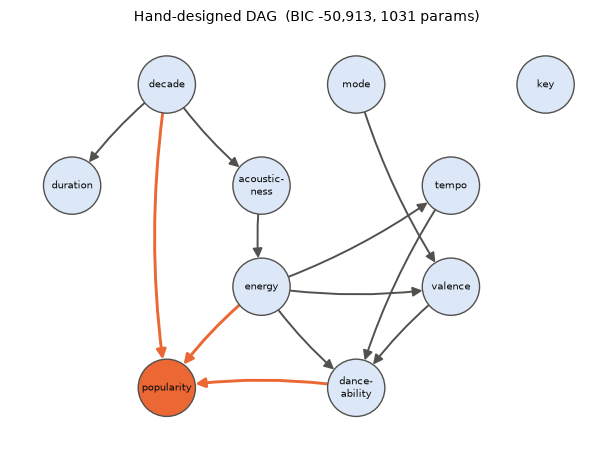

In [6]:
HAND_EDGES = [
    ("acousticness", "energy"), ("energy", "valence"), ("mode", "valence"), ("energy", "tempo"),
    ("energy", "danceability"), ("valence", "danceability"), ("tempo", "danceability"),
    ("decade", "acousticness"), ("decade", "duration"),
    ("energy", "popularity"), ("danceability", "popularity"), ("decade", "popularity"),
]
hand = make_dag(HAND_EDGES)
draw_dag(hand, f"Hand-designed DAG  (BIC {bic(hand):,.0f}, {n_params(hand)} params)", path=FIG_DIR / "dag_hand.png")

## 3. Hill Climb Search with BIC

Hill Climb starts from an empty graph. At each step it takes the single edge addition, deletion or reversal that improves the score the most, and it stops when no move helps. A tabu list prevents it from immediately undoing recent moves. BIC charges $\frac{\log N}{2}\approx 4.1$ nats per free parameter. Popularity has 5 states, so each parent it gains multiplies the size of its CPT, and BIC pays for that.

> **Note on pgmpy:** `HillClimbSearch.estimate(start_dag=g)` *modifies `g` in place*, so we always pass a copy.

Hill Climb + BIC: 9 edges in 0.19s


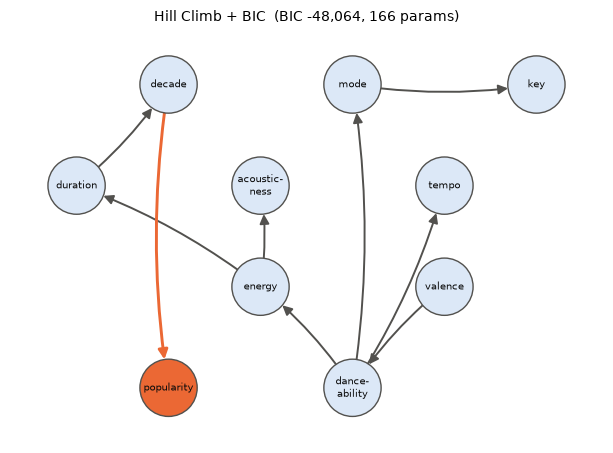

In [7]:
def hc_learn(data, score="bic", ess=None, **kw):
    if "start_dag" in kw: kw["start_dag"] = kw["start_dag"].copy()
    sc = scorer(score, data, **({"equivalent_sample_size": ess} if ess is not None else {}))
    return make_dag(HillClimbSearch(data).estimate(scoring_method=sc, show_progress=False, **kw).edges())

t = time.perf_counter(); hc = hc_learn(train); hc_time = time.perf_counter() - t
print(f"Hill Climb + BIC: {len(hc.edges())} edges in {hc_time:.2f}s")
draw_dag(hc, f"Hill Climb + BIC  (BIC {bic(hc):,.0f}, {n_params(hc)} params)", path=FIG_DIR / "dag_hc.png")

### Hill Climb variants

* **In-degree caps (1, 2):** limit how many parents any node can have.
* **Warm start from the hand DAG:** if Hill Climb deletes or reverses our hand-drawn edges, the data disagrees with them.
* **Popularity as a sink:** forbid every edge out of popularity. Popularity can then only be a child of the audio features, which matches the "features → popularity" story in our proposal and makes $P(\text{pop}\mid\text{parents})$ directly readable.

In [8]:
SINK = lambda: ExpertKnowledge(forbidden_edges=[("popularity", f) for f in FEATURES])
hc_variants = {
    "HC max-indegree=1": hc_learn(train, max_indegree=1),
    "HC max-indegree=2": hc_learn(train, max_indegree=2),
    "HC start=hand": hc_learn(train, start_dag=hand),
    "HC popularity-sink": hc_learn(train, expert_knowledge=SINK()),
}
pd.DataFrame([{"variant": k, "edges": len(g.edges()), "train BIC": round(bic(g), 1),
               "same graph as HC?": set(g.edges()) == set(hc.edges()),
               "pop parents": g.get_parents("popularity"), "pop children": g.get_children("popularity")}
              for k, g in hc_variants.items()]).set_index("variant")

,edges,train BIC,same graph as HC?,pop parents,pop children
variant,,,,,
HC max-indegree=1,9,-48064.1,True,[decade],[]
HC max-indegree=2,9,-48064.1,True,[decade],[]
HC start=hand,9,-48105.5,False,[decade],[acousticness]
HC popularity-sink,9,-48064.1,True,[decade],[]


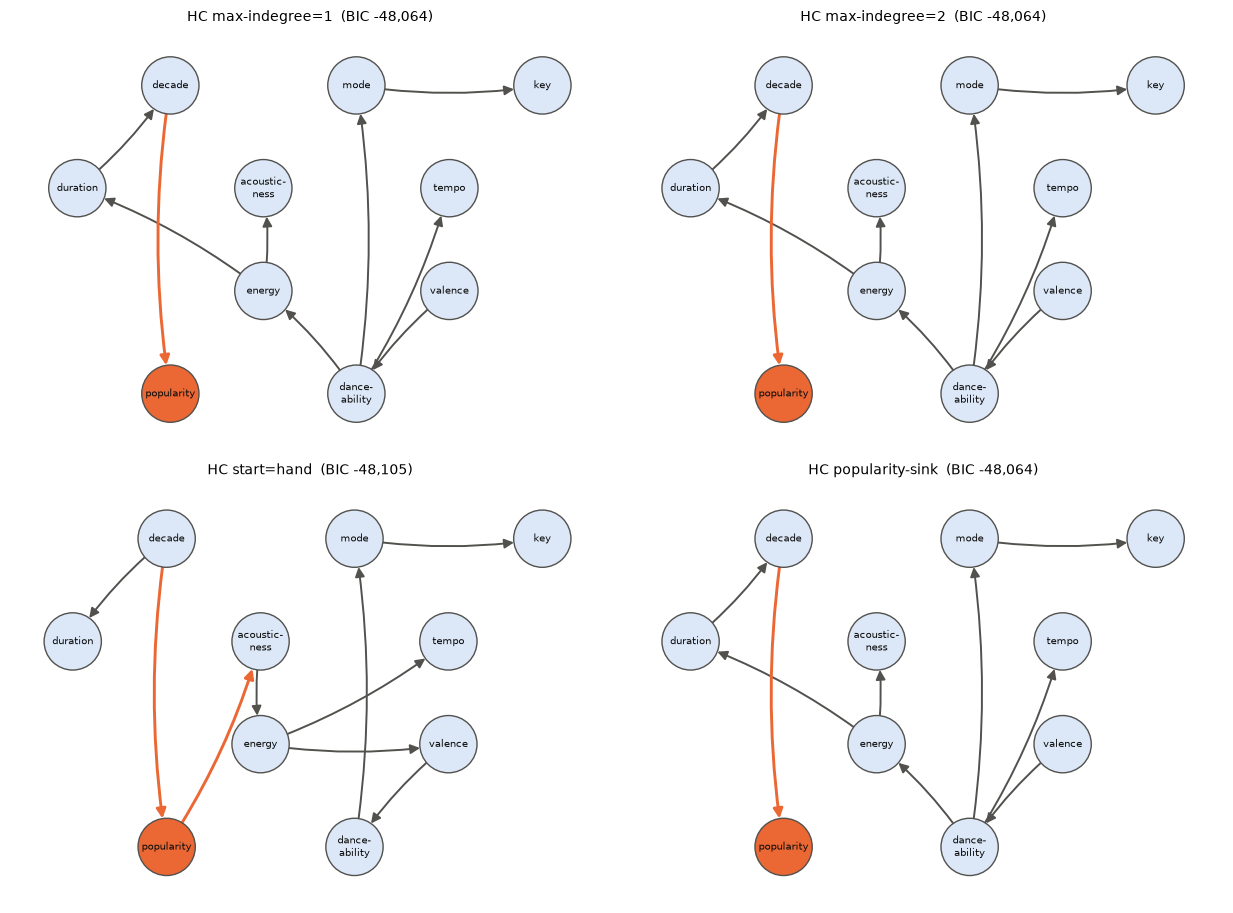

In [9]:
draw_grid(hc_variants, FIG_DIR / "dag_hc_variants.png")

## 4. How much does the score function matter?

BIC's penalty grows with $\log N$. Other scores penalize complexity differently:
* **AIC** charges a flat 1 nat per parameter, so it is far more lenient and tends to keep more edges.
* **K2** and **BDeu** are Bayesian marginal-likelihood scores under a Dirichlet prior. In BDeu, the *equivalent sample size* (ESS) sets how strong that prior is: a larger ESS smooths more, which makes adding parents cheaper.

If an edge survives under every score, we can be confident in it. If it appears only under lenient scores, it is a weak effect.

In [10]:
score_dags = {"HC + BIC": hc,
              "HC + AIC": hc_learn(train, "aic"),
              "HC + K2": hc_learn(train, "k2")}
for ess in [1, 10, 100]:
    score_dags[f"HC + BDeu(ESS={ess})"] = hc_learn(train, "bdeu", ess=ess)

pd.DataFrame([{"score": k, "edges": len(g.edges()), "params": n_params(g), "train BIC": round(bic(g), 1),
               "pop parents": ", ".join(g.get_parents("popularity")) or "-",
               "pop children": ", ".join(g.get_children("popularity")) or "-",
               "pop Markov blanket": ", ".join(popularity_mb(g))}
              for k, g in score_dags.items()]).set_index("score")

,edges,params,train BIC,pop parents,pop children,pop Markov blanket
score,,,,,,
HC + BIC,9,166,-48064.1,decade,-,decade
HC + AIC,14,486,-48653.1,decade,acousticness,"acousticness, decade"
HC + K2,19,6000286,-24585532.1,decade,"acousticness, duration","acousticness, danceability, decade, duration, ..."
HC + BDeu(ESS=1),8,162,-48111.4,decade,acousticness,"acousticness, decade"
HC + BDeu(ESS=10),10,246,-48105.3,acousticness,decade,"acousticness, decade"
HC + BDeu(ESS=100),15,566,-48838.1,acousticness,decade,"acousticness, danceability, decade"


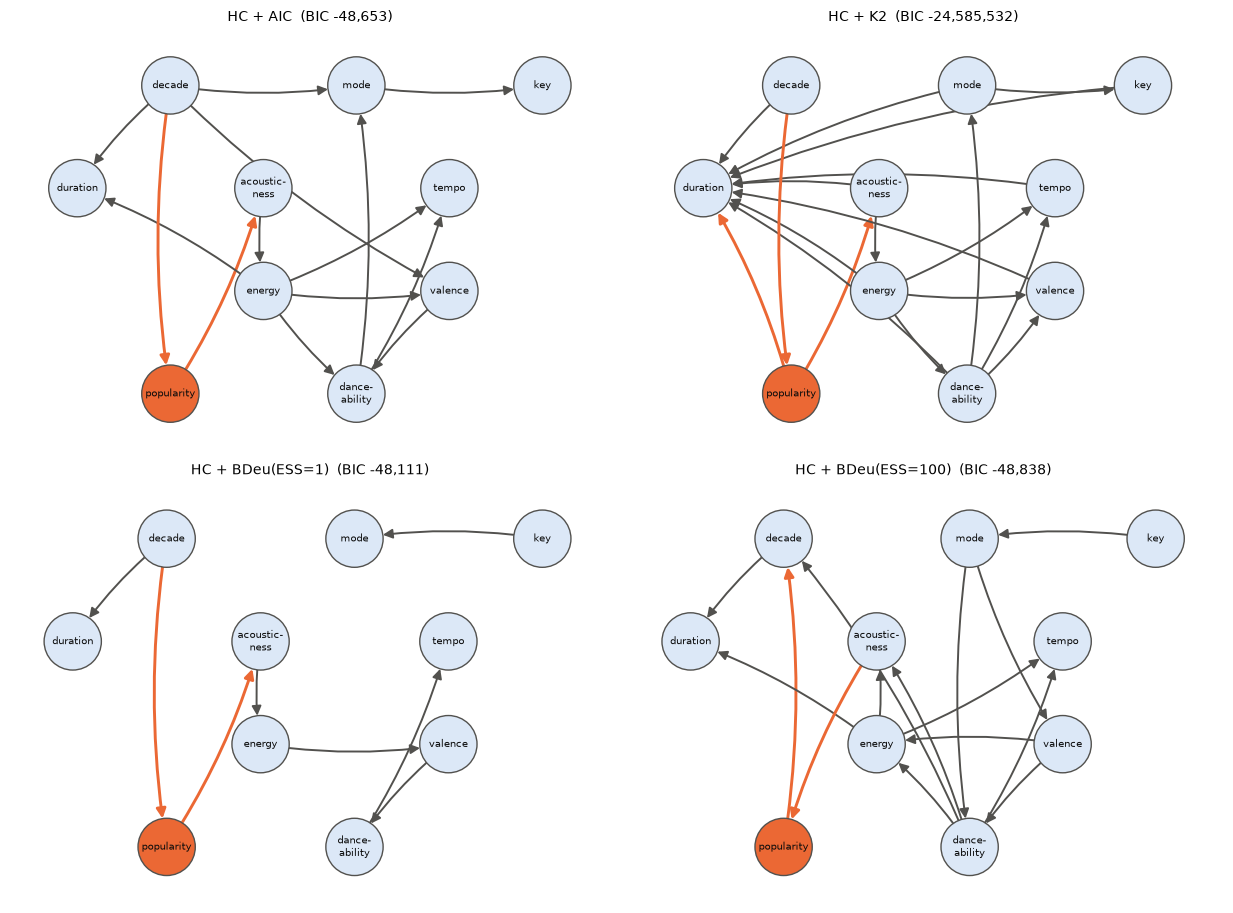

In [11]:
draw_grid({k: score_dags[k] for k in ["HC + AIC", "HC + K2", "HC + BDeu(ESS=1)", "HC + BDeu(ESS=100)"]},
          FIG_DIR / "dag_score_functions.png")

## 5. Other structure-learning algorithms

| Algorithm | Family | What it does |
|---|---|---|
| **PC** (stable variant) | constraint-based | removes an edge whenever a χ² conditional-independence test (α = 0.01) says two variables are independent given some set of others, then orients edges using v-structures |
| **GES** | score-based, over equivalence classes | greedy search over *Markov equivalence classes* using BIC, which avoids Hill Climb's arbitrary choice among equivalent edge directions |
| **Chow-Liu tree** | maximum-likelihood tree | the best tree-shaped network (each node has at most one parent), found as a maximum spanning tree on mutual information |
| **Naive Bayes** | classifier structure | popularity → every feature, with no edges between features |
| **TAN** (tree-augmented naive Bayes) | classifier structure | Naive Bayes plus a Chow-Liu tree among the features, conditioned on popularity |

PC and GES return a partially directed graph (some edges left undirected). We convert it to *one* DAG in the same equivalence class, which has the same BIC and the same likelihood.

In [12]:
def pc_learn(data):
    return make_dag(PC(data).estimate(variant="stable", ci_test="chi_square", significance_level=0.01,
                                      return_type="dag", show_progress=False, n_jobs=1).edges())
def ges_learn(data):
    return make_dag(GES(data).estimate(scoring_method=scorer("bic", data)).to_dag().edges())
def chow_liu_learn(data):
    return make_dag(TreeSearch(data, root_node="popularity", n_jobs=1)
                    .estimate(estimator_type="chow-liu", show_progress=False).edges())
def tan_learn(data):
    return make_dag(TreeSearch(data, root_node="decade", n_jobs=1)
                    .estimate(estimator_type="tan", class_node="popularity", show_progress=False).edges())
naive = make_dag([("popularity", f) for f in FEATURES])

t = time.perf_counter()
algo_dags = {"PC (χ², α=0.01)": pc_learn(train), "GES (BIC)": ges_learn(train),
             "Chow-Liu tree": chow_liu_learn(train), "TAN": tan_learn(train), "Naive Bayes": naive}
print(f"learned in {time.perf_counter() - t:.1f}s")
pd.DataFrame([{"algorithm": k, "edges": len(g.edges()), "params": n_params(g), "train BIC": round(bic(g), 1),
               "pop Markov blanket": ", ".join(popularity_mb(g))} for k, g in algo_dags.items()]).set_index("algorithm")

learned in 15.2s


,edges,params,train BIC,pop Markov blanket
algorithm,,,,
"PC (χ², α=0.01)",9,590,-50097.9,"acousticness, decade, duration"
GES (BIC),9,166,-48048.6,"acousticness, decade"
Chow-Liu tree,9,206,-48199.1,"acousticness, decade"
TAN,17,934,-50510.9,"acousticness, danceability, decade, duration, ..."
Naive Bayes,9,199,-50897.8,"acousticness, danceability, decade, duration, ..."


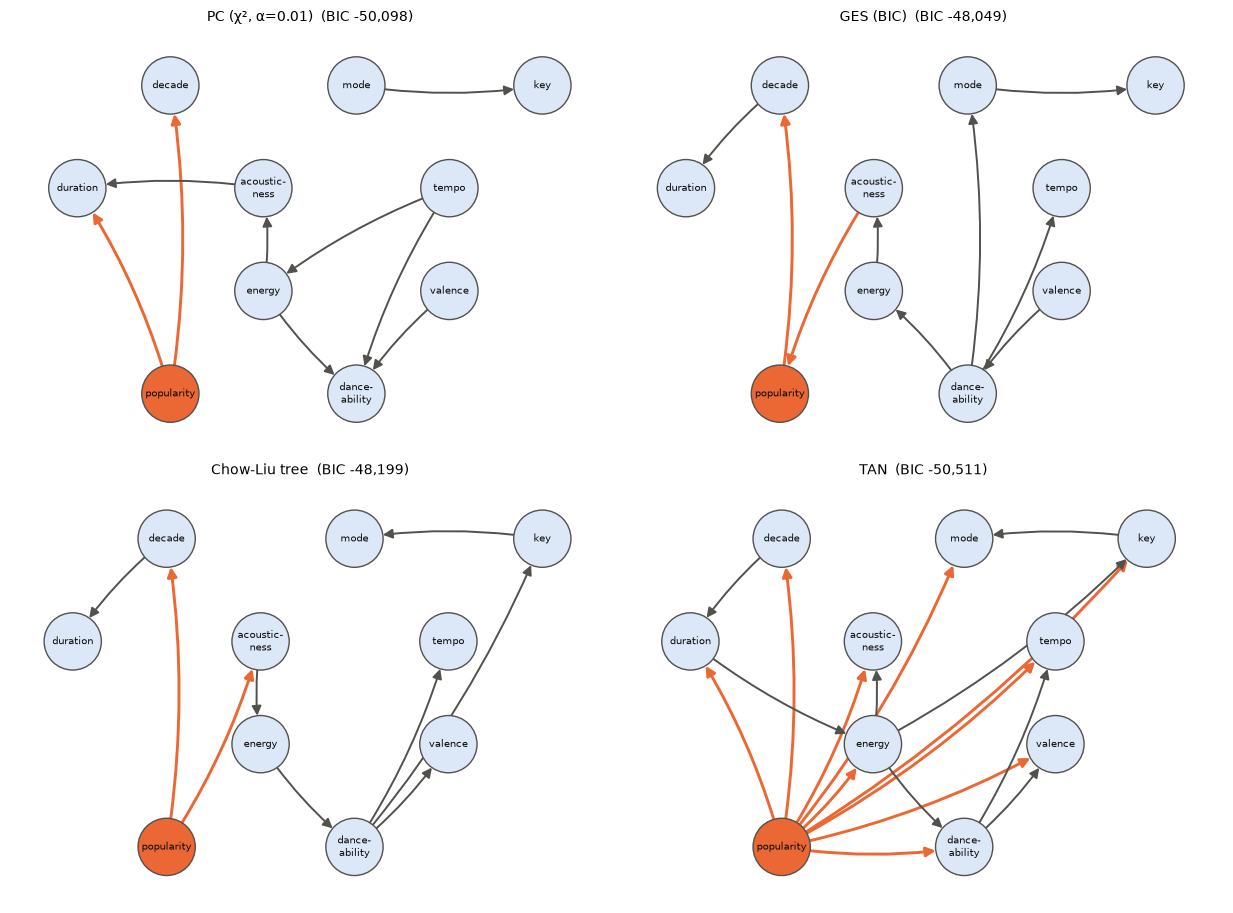

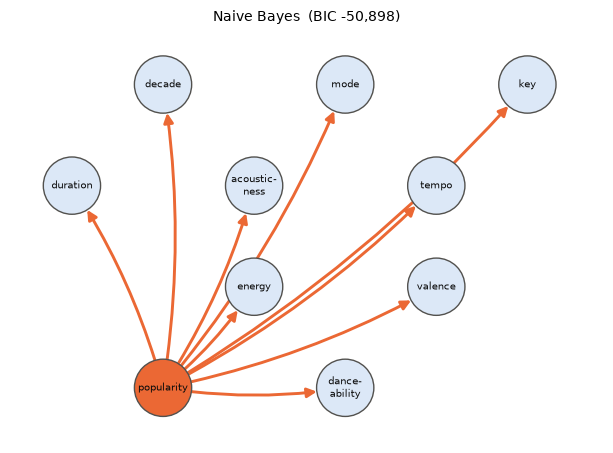

In [13]:
draw_grid({k: algo_dags[k] for k in ["PC (χ², α=0.01)", "GES (BIC)", "Chow-Liu tree", "TAN"]},
          FIG_DIR / "dag_other_algorithms.png")
draw_dag(naive, f"Naive Bayes  (BIC {bic(naive):,.0f})", path=FIG_DIR / "dag_naive_bayes.png")

## 6. How many parents should popularity have?

We keep the hand DAG's feature–feature edges and vary only popularity's parents. For each cap $k = 0,\dots,4$ we search **every** parent set of size $k$ and keep the one with the best BIC. BIC decomposes over nodes, so only popularity's local score changes. This shows directly how much BIC charges for each extra parent compared with how much likelihood that parent buys. We also report each choice's cross-validated log-loss for predicting popularity (lower is better). The parent search is rerun inside each fold.

In [14]:
hand_feature_edges = [e for e in HAND_EDGES if e[1] != "popularity"]
def hand_with_k_pop_parents(data, k):
    sc = scorer("bic", data)
    best = max(itertools.combinations(FEATURES, k), key=lambda ps: sc.local_score("popularity", tuple(ps)))
    return make_dag(hand_feature_edges + [(p, "popularity") for p in best])

FOLDS = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(train))

FOLD_SCORES = {}   # structure name -> per-fold metrics, for paired comparisons

def cv(learner, name=None):
    rows = [evaluate(learner(train.iloc[tr]), train.iloc[tr], train.iloc[va]) for tr, va in FOLDS]
    df = pd.DataFrame(rows)
    if name: FOLD_SCORES[name] = df
    return df.mean(), df.std()

cap_rows, cap_dags = [], {}
for k in range(5):
    g = hand_with_k_pop_parents(train, k)
    cap_dags[f"Hand, best {k} pop parent(s)"] = g
    pa = g.get_parents("popularity")
    mu, sd = cv(lambda d, k=k: hand_with_k_pop_parents(d, k))
    cap_rows.append({"k": k, "parents chosen on full train": ", ".join(pa) or "(none)",
                     "pop CPT params": (CARD["popularity"] - 1) * int(np.prod([CARD[p] for p in pa] or [1])),
                     "Δ pop local BIC vs k=0": bic_scorer.local_score("popularity", tuple(pa))
                                              - bic_scorer.local_score("popularity", ()),
                     "CV pop log-loss": mu["pop log-loss"], "CV pop accuracy": mu["pop accuracy"]})
cap_df = pd.DataFrame(cap_rows).set_index("k")
cap_df.round(3)

,parents chosen on full train,pop CPT params,Δ pop local BIC vs k=0,CV pop log-loss,CV pop accuracy
k,,,,,
0,(none),4,0.000,1.402,0.332
1,decade,20,198.464,1.331,0.463
2,"mode, decade",40,123.360,1.337,0.463
3,"mode, tempo, decade",160,-273.342,1.346,0.456
4,"mode, energy, tempo, decade",800,-2479.072,1.363,0.439


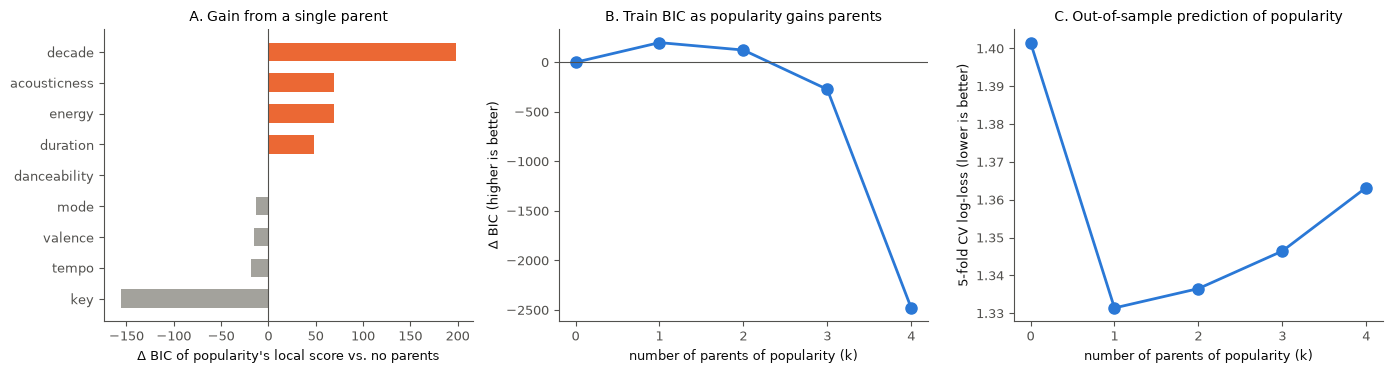

In [15]:
single = pd.Series({f: bic_scorer.local_score("popularity", (f,)) - bic_scorer.local_score("popularity", ())
                    for f in FEATURES}).sort_values()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].barh(single.index, single.values, color=[ORANGE if v > 0 else GREY for v in single.values], height=0.6)
axes[0].axvline(0, color=MUTED, lw=0.8)
axes[0].set_xlabel("Δ BIC of popularity's local score vs. no parents")
axes[0].set_title("A. Gain from a single parent")
axes[1].plot(cap_df.index, cap_df["Δ pop local BIC vs k=0"], "o-", color=BLUE, lw=2, ms=8)
axes[1].axhline(0, color=MUTED, lw=0.8)
axes[1].set_xlabel("number of parents of popularity (k)"); axes[1].set_ylabel("Δ BIC (higher is better)")
axes[1].set_title("B. Train BIC as popularity gains parents"); axes[1].set_xticks(cap_df.index)
axes[2].plot(cap_df.index, cap_df["CV pop log-loss"], "o-", color=BLUE, lw=2, ms=8)
axes[2].set_xlabel("number of parents of popularity (k)"); axes[2].set_ylabel("5-fold CV log-loss (lower is better)")
axes[2].set_title("C. Out-of-sample prediction of popularity"); axes[2].set_xticks(cap_df.index)
plt.tight_layout(); plt.savefig(FIG_DIR / "popularity_parent_cap.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Structure selection by cross-validated predictive fit

BIC alone is not enough to pick a structure, since it is exactly what Hill Climb optimizes. So we also ask how well each structure **predicts popularity from the other nine variables** on data it has not seen. For each of 5 folds of the training set we **rerun the learning algorithm on the other 4 folds**, so the structure search itself is cross-validated, fit the CPTs, and score the held-out fold. Fixed structures (hand-designed, Naive Bayes, decade-only) are simply refit.

> **Scope:** this section is used only to *choose between structures*, and it uses only the training set. Nothing here is computed on `test.csv`, so later choices (pseudocount, which structure to report) cannot be influenced by test results. The official evaluation (accuracy, test log-likelihood and confusion matrix, using the tuned CPTs) belongs to the evaluation stage (Section 4).

For reference:
* **Empty graph:** predicts popularity from its marginal distribution alone.
* **Always the majority class:** the "always medium" baseline. Popularity has 5 bins, and the majority class is (40, 60].

In [16]:
decade_only = make_dag(hand_feature_edges + [("decade", "popularity")])
LEARNERS = {
    "Empty graph (prior only)": lambda d: make_dag([]),
    "Hand-designed": lambda d: hand,
    "Hand, decade-only pop parent": lambda d: decade_only,   # fixed reference: decade → popularity only
    "HC + BIC": lambda d: hc_learn(d),
    "HC popularity-sink": lambda d: hc_learn(d, expert_knowledge=SINK()),
    "HC start=hand": lambda d: hc_learn(d, start_dag=hand),
    "HC + AIC": lambda d: hc_learn(d, "aic"),
    "HC + K2": lambda d: hc_learn(d, "k2"),
    "HC + BDeu(ESS=10)": lambda d: hc_learn(d, "bdeu", ess=10),
    "GES (BIC)": ges_learn,
    "PC (χ², α=0.01)": pc_learn,
    "Chow-Liu tree": chow_liu_learn,
    "Naive Bayes": lambda d: naive,
    "TAN": tan_learn,
}

t = time.perf_counter()
rows, FULL_TRAIN_DAGS = [], {}
for name, learner in LEARNERS.items():
    mu, sd = cv(learner, name)
    g = FULL_TRAIN_DAGS[name] = learner(train)
    rows.append({"structure": name, "edges": len(g.edges()), "params": n_params(g), "train BIC": bic(g),
                 "CV pop log-loss": mu["pop log-loss"], "CV log-loss sd": sd["pop log-loss"],
                 "CV pop acc": mu["pop accuracy"], "CV acc sd": sd["pop accuracy"],
                 "SHD vs hand": shd(g, hand),
                 "pop Markov blanket": ", ".join(popularity_mb(g)) or "-"})
print(f"cross-validated {len(LEARNERS)} learners in {time.perf_counter() - t:.0f}s")

maj_cv = np.mean([(train.iloc[va].popularity == train.iloc[tr].popularity.mode()[0]).mean() for tr, va in FOLDS])
results = pd.DataFrame(rows).set_index("structure").sort_values("CV pop log-loss")
results.to_csv(MODEL_DIR / "structure_comparison.csv")
print(f"Always-majority baseline: CV accuracy {maj_cv:.3f}")
results.drop(columns=["CV log-loss sd", "CV acc sd"]).round(3)

cross-validated 14 learners in 81s
Always-majority baseline: CV accuracy 0.332


,edges,params,train BIC,CV pop log-loss,CV pop acc,SHD vs hand,pop Markov blanket
structure,,,,,,,
HC start=hand,9,166,-4.810548e+04,1.306,0.469,9,"acousticness, decade"
HC + K2,19,6000286,-2.458553e+07,1.308,0.467,17,"acousticness, danceability, decade, duration, ..."
Chow-Liu tree,9,206,-4.819907e+04,1.311,0.466,12,"acousticness, decade"
HC + BDeu(ESS=10),10,246,-4.810528e+04,1.311,0.466,13,"acousticness, decade"
GES (BIC),9,166,-4.804858e+04,1.311,0.466,13,"acousticness, decade"
HC + BIC,9,166,-4.806411e+04,1.312,0.463,13,decade
HC + AIC,14,486,-4.865313e+04,1.312,0.468,11,"acousticness, decade"
Hand-designed,12,1031,-5.091313e+04,1.321,0.459,0,"danceability, decade, energy"
"Hand, decade-only pop parent",10,551,-4.933511e+04,1.331,0.463,2,decade


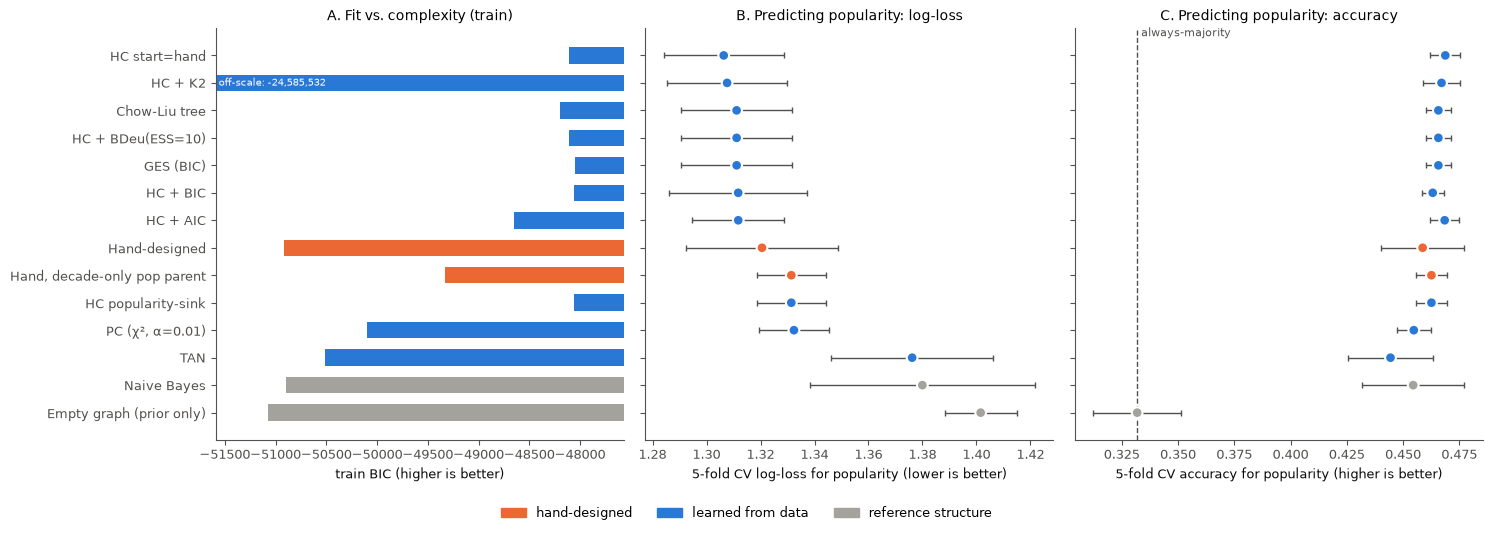

In [17]:
order = results.index[::-1]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
y = np.arange(len(order))
colors = [ORANGE if n.startswith("Hand") else (GREY if n.startswith(("Empty", "Naive")) else BLUE) for n in order]

# K2 puts 9 parents on one node, so its BIC is orders of magnitude off-scale: clip and label it
bic_vals = results.loc[order, "train BIC"]
lo = bic_vals[bic_vals > -1e6].min() * 1.01
axes[0].barh(y, bic_vals.clip(lower=lo), color=colors, height=0.6)
axes[0].set_xlim(lo, results["train BIC"].max() * 0.99)
for yi, v in zip(y, bic_vals):
    if v < lo: axes[0].text(lo, yi, f" off-scale: {v:,.0f}", va="center", fontsize=7.5, color="white")
axes[0].set_xlabel("train BIC (higher is better)"); axes[0].set_title("A. Fit vs. complexity (train)")

for ax, col, sdcol, lab, ttl in [(axes[1], "CV pop log-loss", "CV log-loss sd", "5-fold CV log-loss for popularity (lower is better)", "B. Predicting popularity: log-loss"),
                                 (axes[2], "CV pop acc", "CV acc sd", "5-fold CV accuracy for popularity (higher is better)", "C. Predicting popularity: accuracy")]:
    ax.errorbar(results.loc[order, col], y, xerr=results.loc[order, sdcol], fmt="none", ecolor=MUTED, elinewidth=1, capsize=2)
    ax.scatter(results.loc[order, col], y, c=colors, s=60, zorder=3, edgecolors="white", linewidths=1.5)
    ax.set_xlabel(lab); ax.set_title(ttl)
axes[2].axvline(maj_cv, color=MUTED, ls="--", lw=1)
axes[2].text(maj_cv, len(order) - 0.4, " always-majority", color=MUTED, fontsize=8, va="bottom")

axes[0].set_yticks(y, order)
fig.legend(handles=[Patch(color=ORANGE, label="hand-designed"), Patch(color=BLUE, label="learned from data"),
                    Patch(color=GREY, label="reference structure")], loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.03))
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(FIG_DIR / "structure_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

### Are the differences real? A paired comparison across folds

The fold-to-fold spread (about 0.02 nats) is as large as the gaps between structures. But every structure is scored on the **same** five folds, so the right test is paired: for each fold, take the difference between a structure's log-loss and a reference's log-loss. Then report the mean difference, its standard deviation, and how many of the 5 folds favour the structure. The reference is *decade-only*: the hand DAG's feature edges with **decade → popularity hard-wired** as popularity's only edge, identical in every fold. This asks whether adding audio features to popularity's neighbourhood helps at all.

In [18]:
REF = "Hand, decade-only pop parent"
ref = FOLD_SCORES[REF]["pop log-loss"].to_numpy()
paired = []
for name, df in FOLD_SCORES.items():
    if name == REF: continue
    d = df["pop log-loss"].to_numpy() - ref
    se = d.std(ddof=1) / np.sqrt(len(d))
    paired.append({"structure": name, "mean Δ log-loss vs decade-only": d.mean(), "sd of Δ": d.std(ddof=1),
                   "paired t": d.mean() / se if se > 0 else np.nan, "folds better (of 5)": int((d < 0).sum()),
                   "pop Markov blanket": results.loc[name, "pop Markov blanket"]})
paired = pd.DataFrame(paired).set_index("structure").sort_values("mean Δ log-loss vs decade-only")
paired.to_csv(MODEL_DIR / "paired_cv_vs_decade_only.csv")
paired.round(4)

,mean Δ log-loss vs decade-only,sd of Δ,paired t,folds better (of 5),pop Markov blanket
structure,,,,,
HC start=hand,-0.0250,0.0141,-3.9744,5,"acousticness, decade"
HC + K2,-0.0238,0.0142,-3.7369,5,"acousticness, danceability, decade, duration, ..."
Chow-Liu tree,-0.0203,0.0099,-4.5733,5,"acousticness, decade"
HC + BDeu(ESS=10),-0.0203,0.0099,-4.5767,5,"acousticness, decade"
GES (BIC),-0.0203,0.0099,-4.5767,5,"acousticness, decade"
HC + BIC,-0.0197,0.0140,-3.1539,4,decade
HC + AIC,-0.0197,0.0104,-4.2229,5,"acousticness, decade"
Hand-designed,-0.0109,0.0168,-1.4459,3,"danceability, decade, energy"
HC popularity-sink,0.0000,0.0000,NaN,0,decade


### Which feature carries the extra signal?

The learned structures add acousticness next to decade. But Hill Climb + BIC, rerun inside each fold, adds *energy* in some folds instead, and energy is strongly correlated with acousticness (NMI 0.23). To find out which feature matters, we fix popularity's parents directly: decade plus one feature, and decade plus both acousticness and energy. The feature edges are the hand DAG's and popularity has no children, so popularity's Markov blanket is exactly the listed parents. Each set is paired against decade-only on the same folds.

In [19]:
PARENT_SETS = [("decade", "acousticness"), ("decade", "energy"), ("decade", "danceability"),
               ("decade", "duration"), ("decade", "acousticness", "energy")]
second = []
for ps in PARENT_SETS:
    name = "pop ← " + " + ".join(ps)
    mu, _ = cv(lambda d, ps=ps: make_dag(hand_feature_edges + [(p, "popularity") for p in ps]), name)
    d = FOLD_SCORES[name]["pop log-loss"].to_numpy() - ref
    second.append({"popularity's parents": " + ".join(ps), "pop CPT params": (CARD["popularity"] - 1) * int(np.prod([CARD[p] for p in ps])),
                   "CV pop log-loss": mu["pop log-loss"], "CV pop acc": mu["pop accuracy"],
                   "mean Δ vs decade-only": d.mean(), "paired t": d.mean() / (d.std(ddof=1) / np.sqrt(len(d))),
                   "folds better (of 5)": int((d < 0).sum())})
second = pd.DataFrame(second).set_index("popularity's parents")
second.to_csv(MODEL_DIR / "second_parent_cv.csv")
second.round(4)

,pop CPT params,CV pop log-loss,CV pop acc,mean Δ vs decade-only,paired t,folds better (of 5)
popularity's parents,,,,,,
decade + acousticness,100,1.3083,0.4702,-0.0231,-4.1552,5
decade + energy,100,1.3073,0.4674,-0.0242,-7.9355,5
decade + danceability,100,1.3242,0.4674,-0.0072,-1.4397,4
decade + duration,100,1.3293,0.4573,-0.0021,-0.7402,3
decade + acousticness + energy,500,1.3256,0.4607,-0.0058,-0.7851,3


## 8. Bootstrap edge stability and consensus DAG

Hill Climb is greedy, and a different sample of songs could produce a different graph. We rerun Hill Climb + BIC on 200 bootstrap resamples of the training set and count how often each edge appears in either direction. An edge that appears in nearly every resample is well supported. One that appears only sometimes is fragile.

The **consensus DAG** keeps every edge that appears in at least 50% of runs, points it in its most common direction, and adds edges from most to least frequent, skipping any that would create a cycle.

In [20]:
rng = np.random.default_rng(SEED)
B = 200
edge_counts, dir_counts = Counter(), Counter()
for _ in range(B):
    boot = train.sample(len(train), replace=True, random_state=int(rng.integers(1e9)))
    g = HillClimbSearch(boot).estimate(scoring_method=scorer("bic", boot), show_progress=False)
    for a, b in g.edges():
        edge_counts[frozenset((a, b))] += 1; dir_counts[(a, b)] += 1

hand_skel, hc_skel = skeleton(hand), skeleton(hc)
stab = []
for pair, c in edge_counts.items():
    a, b = sorted(pair)
    d = max([(a, b), (b, a)], key=lambda e: dir_counts[e])
    stab.append({"edge": f"{a} — {b}", "frequency": c / B,
                 "direction": f"{d[0]} → {d[1]}", "direction agreement": dir_counts[d] / c,
                 "in HC": pair in hc_skel, "in hand DAG": pair in hand_skel, "_dir": d})
stab = pd.DataFrame(stab).sort_values("frequency", ascending=False).reset_index(drop=True)
stab.drop(columns=["_dir"]).to_csv(MODEL_DIR / "bootstrap_edge_stability.csv", index=False)

consensus = make_dag([])
for d in stab.loc[stab.frequency >= 0.5, "_dir"]:
    consensus.add_edge(*d)
    if not nx.is_directed_acyclic_graph(consensus): consensus.remove_edge(*d)
stab.drop(columns=["_dir"]).head(20).round(3)

,edge,frequency,direction,direction agreement,in HC,in hand DAG
0,key — mode,1.000,mode → key,0.840,True,False
1,decade — popularity,1.000,decade → popularity,0.770,True,True
2,decade — duration,1.000,duration → decade,0.685,True,True
3,acousticness — energy,1.000,energy → acousticness,0.795,True,True
4,danceability — valence,0.995,valence → danceability,0.613,True,True
5,danceability — energy,0.905,danceability → energy,0.674,True,True
6,danceability — mode,0.830,danceability → mode,0.946,True,False
7,danceability — tempo,0.750,danceability → tempo,0.973,True,True
8,duration — energy,0.450,energy → duration,0.944,True,False
9,energy — tempo,0.250,energy → tempo,0.980,False,True


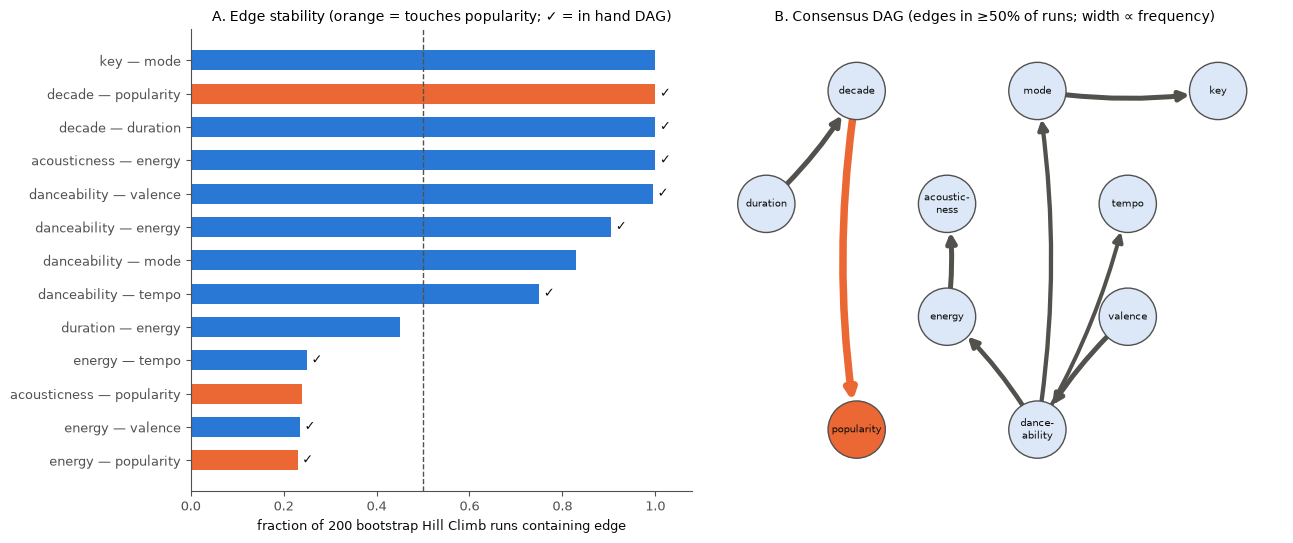

consensus DAG BIC: -48118.1 | same skeleton as HC: False


In [21]:
top = stab[stab.frequency >= 0.05].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(13, max(4.8, 0.3 * len(top) + 1.6)), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
ax.barh(top.edge, top.frequency, color=[ORANGE if "popularity" in e else BLUE for e in top.edge], height=0.6)
ax.invert_yaxis(); ax.axvline(0.5, ls="--", color=MUTED, lw=1)
ax.set_xlim(0, 1.08); ax.set_xlabel(f"fraction of {B} bootstrap Hill Climb runs containing edge")
ax.set_title("A. Edge stability (orange = touches popularity; ✓ = in hand DAG)")
for i, r in top.iterrows():
    if r["in hand DAG"]: ax.text(r.frequency + 0.01, i, "✓", va="center", color=INK, fontsize=9)
widths = {r["_dir"]: r["frequency"] for _, r in stab.iterrows()}
draw_dag(consensus, "B. Consensus DAG (edges in ≥50% of runs; width ∝ frequency)", ax=axes[1], widths=widths)
plt.tight_layout(); plt.savefig(FIG_DIR / "bootstrap_consensus.png", dpi=200, bbox_inches="tight"); plt.show()
print("consensus DAG BIC:", round(bic(consensus), 1), "| same skeleton as HC:", skeleton(consensus) == hc_skel)

## 9. Hand DAG vs. learned DAG, compared up to Markov equivalence

Two DAGs are **Markov equivalent** (they encode exactly the same conditional independencies and have the same BIC) if and only if they share the same **skeleton** (the edges with direction ignored) and the same **v-structures** ($a \to c \leftarrow b$ with $a$ and $b$ not adjacent). Observational data cannot tell equivalent DAGs apart. So when Hill Climb reverses one of our edges, that is evidence against us only if the reversal changes a v-structure. The fair comparison is therefore skeletons plus v-structures, not raw edge directions.

In [22]:
def compare(g_ref, g, name):
    s_ref, s = skeleton(g_ref), skeleton(g)
    fmt = lambda S: sorted(" — ".join(sorted(e)) for e in S)
    print(f"=== hand DAG vs {name} ===")
    print(f"skeleton: {len(s_ref & s)} shared, {len(s_ref - s)} only in hand, {len(s - s_ref)} only in {name}")
    print("  shared    :", fmt(s_ref & s))
    print("  hand only :", fmt(s_ref - s))
    print(f"  {name} only:", fmt(s - s_ref))
    print("  v-structures in hand :", sorted(f"{a} → {c} ← {b}" for a, c, b in vstructures(g_ref)))
    print(f"  v-structures in {name}:", sorted(f"{a} → {c} ← {b}" for a, c, b in vstructures(g)))
    print()
compare(hand, hc, "HC + BIC")
compare(hand, consensus, "consensus")

=== hand DAG vs HC + BIC ===
skeleton: 6 shared, 6 only in hand, 3 only in HC + BIC
  shared    : ['acousticness — energy', 'danceability — energy', 'danceability — tempo', 'danceability — valence', 'decade — duration', 'decade — popularity']
  hand only : ['acousticness — decade', 'danceability — popularity', 'energy — popularity', 'energy — tempo', 'energy — valence', 'mode — valence']
  HC + BIC only: ['danceability — mode', 'duration — energy', 'key — mode']
  v-structures in hand : ['danceability → popularity ← decade', 'decade → popularity ← energy', 'energy → valence ← mode', 'tempo → danceability ← valence']
  v-structures in HC + BIC: []

=== hand DAG vs consensus ===
skeleton: 6 shared, 6 only in hand, 2 only in consensus
  shared    : ['acousticness — energy', 'danceability — energy', 'danceability — tempo', 'danceability — valence', 'decade — duration', 'decade — popularity']
  hand only : ['acousticness — decade', 'danceability — popularity', 'energy — popularity', 'energy

## Report assets

The full report gets 7 pages for Sections 1–6, shared by five stages, so §3's structure part should fit in about one figure and one table. This section produces both, generated from the results above so they can't drift out of sync with the notebook:
* `figures/structure/report_dags.png`: the hand DAG, Hill Climb + BIC and HC start=hand, side by side.
* `models/structure_table.tex`: a booktabs table for Overleaf (needs `\usepackage{booktabs}`).

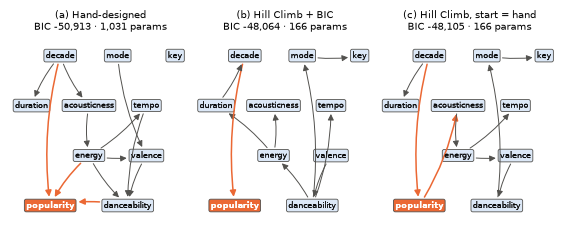

In [23]:
# Drawn at exactly the 5.5in NeurIPS text width, so it is included at 100% scale and fonts print at their true 6-7pt size
POS_C = {**POS, "popularity": (-0.35, 0.0), "danceability": (2.35, 0.0)}   # bottom row spread out so its edge stays visible

def draw_dag_compact(g, title, ax):
    boxes = {}
    for n, (x, y) in POS_C.items():
        pop = n == "popularity"
        style = dict(ha="center", va="center", fontsize=6, color="white" if pop else INK, fontweight="bold" if pop else "normal")
        boxes[n] = ax.text(x, y, n, zorder=3, bbox=dict(boxstyle="round,pad=0.22", fc=ORANGE if pop else "#dce8f7", ec=MUTED, lw=0.6), **style)
        ax.text(x, y, n, zorder=5, **style)           # repeat the text above any arrow that crosses a box
    for a, b in g.edges():
        pop = "popularity" in (a, b)
        ax.annotate("", xy=POS_C[b], xytext=POS_C[a], zorder=4,   # drawn after the boxes, so it clips to their final size
                    arrowprops=dict(arrowstyle="-|>,head_length=0.4,head_width=0.2", lw=1.1 if pop else 0.7,
                                    color=ORANGE if pop else MUTED, shrinkA=1.5, shrinkB=1.5,
                                    patchA=boxes[a].get_bbox_patch(), patchB=boxes[b].get_bbox_patch(),
                                    connectionstyle="arc3,rad=0.1"))
    ax.set_title(title, fontsize=7); ax.axis("off"); ax.set_xlim(-1.75, 4.55); ax.set_ylim(-0.35, 3.35)

trio = {"(a) Hand-designed": hand, "(b) Hill Climb + BIC": hc, "(c) Hill Climb, start = hand": hc_variants["HC start=hand"]}
fig, axes = plt.subplots(1, 3, figsize=(5.5, 2.15))
for ax, (name, g) in zip(axes, trio.items()):
    draw_dag_compact(g, f"{name}\nBIC {bic(g):,.0f} · {n_params(g):,} params", ax)
fig.subplots_adjust(left=0, right=1, bottom=0, top=0.86, wspace=0.02)
plt.savefig(FIG_DIR / "report_dags.png", dpi=300); plt.show()   # no bbox_inches="tight", so the width stays exactly 5.5in

In [24]:
TABLE_ROWS = [  # (name in results, display name)
    ("Hand-designed", "Hand-designed (proposal)"),
    ("HC + BIC", "HC + BIC"),
    ("HC start=hand", "HC + BIC, start = hand"),
    ("GES (BIC)", "GES (BIC)"),
    ("HC + AIC", "HC + AIC"),
    ("HC + BDeu(ESS=10)", "HC + BDeu (ESS 10)"),
    ("HC + K2", "HC + K2"),
    ("PC (χ², α=0.01)", r"PC ($\chi^2$, $\alpha{=}0.01$)"),
    ("Chow-Liu tree", "Chow-Liu tree"),
    ("TAN", "TAN"),
    ("Naive Bayes", "Naive Bayes"),
    ("Hand, decade-only pop parent", "Hand, decade $\\to$ pop.\\ only"),
    ("Empty graph (prior only)", "Empty graph (prior only)"),
]
best_ll = results["CV pop log-loss"].min()

def num(x):
    # LaTeX math-mode number with thousands separators and a real minus sign
    if x <= -1e6:
        return rf"$\approx -{abs(x) / 1e6:.1f}\,\mathrm{{M}}$"
    return "$" + f"{x:,.0f}".replace(",", "{,}") + "$"

lines = [r"\setlength{\tabcolsep}{4pt}", r"\begin{tabular}{lrrrcc}", r"\toprule",
         r"Structure & Edges & Params & Train BIC & CV log-loss $\downarrow$ & CV acc.\ $\uparrow$ \\", r"\midrule"]
for key, disp in TABLE_ROWS:
    r = results.loc[key]
    ll = f"{r['CV pop log-loss']:.3f}"
    if np.isclose(r["CV pop log-loss"], best_ll): ll = rf"\textbf{{{ll}}}"
    lines.append(f"{disp} & {int(r['edges'])} & {num(r['params'])} & {num(r['train BIC'])} & {ll} & {r['CV pop acc']:.3f} \\\\")
    if key in ("Hand-designed", "Naive Bayes"): lines.append(r"\midrule")
lines += [r"\bottomrule", r"\end{tabular}"]
tex = "\n".join(lines)
(MODEL_DIR / "structure_table.tex").write_text(tex + "\n")
print(tex)
print(f"\nAlways-majority accuracy (CV): {maj_cv:.3f}")

\setlength{\tabcolsep}{4pt}
\begin{tabular}{lrrrcc}
\toprule
Structure & Edges & Params & Train BIC & CV log-loss $\downarrow$ & CV acc.\ $\uparrow$ \\
\midrule
Hand-designed (proposal) & 12 & $1{,}031$ & $-50{,}913$ & 1.321 & 0.459 \\
\midrule
HC + BIC & 9 & $166$ & $-48{,}064$ & 1.312 & 0.463 \\
HC + BIC, start = hand & 9 & $166$ & $-48{,}105$ & \textbf{1.306} & 0.469 \\
GES (BIC) & 9 & $166$ & $-48{,}049$ & 1.311 & 0.466 \\
HC + AIC & 14 & $486$ & $-48{,}653$ & 1.312 & 0.468 \\
HC + BDeu (ESS 10) & 10 & $246$ & $-48{,}105$ & 1.311 & 0.466 \\
HC + K2 & 19 & $6{,}000{,}286$ & $\approx -24.6\,\mathrm{M}$ & 1.308 & 0.467 \\
PC ($\chi^2$, $\alpha{=}0.01$) & 9 & $590$ & $-50{,}098$ & 1.332 & 0.455 \\
Chow-Liu tree & 9 & $206$ & $-48{,}199$ & 1.311 & 0.466 \\
TAN & 17 & $934$ & $-50{,}511$ & 1.376 & 0.444 \\
Naive Bayes & 9 & $199$ & $-50{,}898$ & 1.380 & 0.454 \\
\midrule
Hand, decade $\to$ pop.\ only & 10 & $551$ & $-49{,}335$ & 1.331 & 0.463 \\
Empty graph (prior only) & 0 & $43$ & $-51

## 10. Export structures

The other stages (parameter learning, Variable Elimination, Gibbs sampling and evaluation) should load graphs from this file so that everyone uses identical structures. `bn_structures.py` in the repo root wraps the loading step:

```python
from pgmpy.parameter_estimator import DiscreteBayesianEstimator   # pgmpy >= 1.1 API
from bn_structures import load_structure, list_structures, load_split

train_df, test_df = load_split()
from bn_structures import state_names
model = load_structure("HC + BIC")          # pgmpy DiscreteBayesianNetwork, CPTs not yet fitted
model.fit(train_df, estimator=DiscreteBayesianEstimator(state_names=state_names(),
                                                        prior_type="BDeu", equivalent_sample_size=5))
```

In [25]:
exported = {**FULL_TRAIN_DAGS, **hc_variants, **score_dags, **algo_dags, **cap_dags, "Bootstrap consensus": consensus}
for name in FULL_TRAIN_DAGS:   # the same name must mean the same graph everywhere
    assert set(exported[name].edges()) == set(FULL_TRAIN_DAGS[name].edges()), name
export = {name: {"nodes": VARS, "edges": [list(e) for e in sorted(g.edges())],
                 "train_bic": round(bic(g), 2), "n_params": n_params(g),
                 "popularity_markov_blanket": popularity_mb(g)}
          for name, g in exported.items()}
export["_states"] = STATES   # full state space: pass as state_names when fitting CPTs
export["_recommended"] = {"main_learned": "HC + BIC", "best_bic": "GES (BIC)", "proposal": "Hand-designed",
                          "best_predictive": results.index[0], "for_feature_queries": "HC start=hand",
                          "note": "see the Findings section of structure_learning.ipynb"}
for role, name in export["_recommended"].items():
    assert role == "note" or name in export, (role, name)
with open(MODEL_DIR / "structures.json", "w") as f:
    json.dump(export, f, indent=2)
print(f"Wrote {len(exported)} structures to {MODEL_DIR / 'structures.json'}; best predictive = {results.index[0]}")

Wrote 24 structures to models/structures.json; best predictive = HC start=hand


## Key numbers behind the findings

This cell collects every number the Findings text quotes, straight from the tables above, so the text can be checked against it after any rerun.

In [26]:
mb = lambda n: set(popularity_mb(exported[n]))
print("NMI with popularity:", nmi.loc["popularity"].drop("popularity").sort_values(ascending=False).round(3).to_dict())
print(f"BIC  HC={bic(hc):,.0f}  GES={bic(algo_dags['GES (BIC)']):,.0f}  hand={bic(hand):,.0f}  | params HC={n_params(hc)} hand={n_params(hand)}")
print("best k for popularity parents by BIC:", int(cap_df['Δ pop local BIC vs k=0'].idxmax()))
print("score function -> pop Markov blanket:", {k: sorted(mb(k)) for k in score_dags})
print("Markov blankets that ever contain energy:", [k for k in exported if not k.startswith("_") and "energy" in mb(k)])
print()
print(results[["CV pop log-loss", "CV pop acc"]].round(3).to_string())
print(f"majority-class accuracy (CV): {maj_cv:.3f}")
print()
print(paired[["mean Δ log-loss vs decade-only", "paired t", "folds better (of 5)", "pop Markov blanket"]].round(3).to_string())
print()
print(second[["CV pop log-loss", "mean Δ vs decade-only", "paired t", "folds better (of 5)"]].round(4).to_string())
print()
print("bootstrap frequencies:", stab.set_index("edge")["frequency"].head(14).to_dict())
print("v-structures hand:", len(vstructures(hand)), "| HC:", len(vstructures(hc)))

NMI with popularity: {'decade': 0.057, 'acousticness': 0.027, 'energy': 0.026, 'duration': 0.023, 'danceability': 0.013, 'valence': 0.009, 'tempo': 0.006, 'key': 0.003, 'mode': 0.001}
BIC  HC=-48,064  GES=-48,049  hand=-50,913  | params HC=166 hand=1031
best k for popularity parents by BIC: 1
score function -> pop Markov blanket: {'HC + BIC': ['decade'], 'HC + AIC': ['acousticness', 'decade'], 'HC + K2': ['acousticness', 'danceability', 'decade', 'duration', 'energy', 'key', 'mode', 'tempo', 'valence'], 'HC + BDeu(ESS=1)': ['acousticness', 'decade'], 'HC + BDeu(ESS=10)': ['acousticness', 'decade'], 'HC + BDeu(ESS=100)': ['acousticness', 'danceability', 'decade']}
Markov blankets that ever contain energy: ['Hand-designed', 'HC + K2', 'Naive Bayes', 'TAN', 'Hand, best 4 pop parent(s)']

                              CV pop log-loss  CV pop acc
structure                                                
HC start=hand                           1.306       0.469
HC + K2                       

## Findings (draft text for Section 3)

*Every number here appears in the "Key numbers" cell above (run with `PYTHONHASHSEED=0` on the frozen split). After any rerun, re-check the text against that cell.*

**1. Popularity is only weakly related to any single variable, and release decade dominates.** Popularity's normalized mutual information with every variable is ≤ 0.06. The largest is with decade (0.057), followed by acousticness (0.027) and energy (0.026). For comparison, acousticness and energy have NMI 0.23 with each other.

**2. Hill Climb + BIC vs. the hand-designed DAG.** Hill Climb learns a sparse 9-edge, 166-parameter graph (BIC −48,064). The hand DAG has 1,031 parameters and scores −50,913. Most of that gap is popularity's CPT: our three parents (energy, danceability, decade) cost 4 × 5³ = 500 parameters. When we search every possible parent set exhaustively, **one parent (decade) is BIC-optimal**. With 2 parents BIC falls, and with 3 or more it falls below having no parents at all. Neither in-degree caps nor forcing popularity to be a sink changes the learned graph. GES, which searches over Markov equivalence classes, finds a slightly better optimum (BIC −48,049) that adds acousticness–popularity. So greedy Hill Climb stopped just short of that edge.

**3. Which of our assumptions hold up?** Comparing only what is identifiable (skeletons and v-structures), the hand DAG and Hill Climb share 6 adjacencies. Five of them appear in ≥ 90% of 200 bootstrap runs: acousticness–energy, valence–danceability, energy–danceability, decade–duration and decade–popularity. Danceability–tempo appears in 75%. Edges that are weak or unsupported:
* **energy → valence** (from the proposal) appears in 24% of bootstrap runs, and energy → tempo in 25%.
* **mode → valence** and **decade → acousticness** appear in ≤ 1%.
* **All 4 v-structures in the hand DAG are rejected** (for example energy → valence ← mode). The learned graph has no v-structures at all.

The data also adds edges we did not anticipate: mode–key (100%) and danceability–mode (83%). Edge directions are often close to coin flips across bootstrap runs (61–84% agreement for the most stable edges), as expected for edges inside a Markov equivalence class. So a "reversed" edge is not evidence against the hand DAG.

**4. Score sensitivity.** BIC gives popularity the Markov blanket {decade}. AIC and BDeu with ESS = 1 or 10 all give {decade, acousticness}. BDeu with ESS = 100 adds danceability. K2, which has almost no complexity penalty at this sample size, connects popularity to every variable and gives duration 9 parents (about 6M parameters). None of the score-based searches on the full training set picks energy for popularity's blanket (only K2, which takes every variable). Energy does appear in the hand-designed and classifier-style (Naive Bayes, TAN) structures, and Hill Climb + BIC picks it in 3 of 5 CV folds. As item 6 shows, the searches' preference for acousticness over energy is close to arbitrary.

**5. Choosing a structure by cross-validated predictive fit (training set only).** Most learned structures predict popularity with a log-loss of about 1.31 and about 46–47% accuracy. For comparison, the prior alone scores 1.40 and always predicting the majority class gives 33% accuracy. In a paired comparison against the *decade-only* reference (decade → popularity hard-wired), these structures beat it on **all 5 folds** with Δ log-loss of −0.020 to −0.025:
* HC start=hand, HC + AIC, HC + BDeu(10), GES and Chow-Liu, whose Markov blanket is {decade, acousticness} (paired t from −4.0 to −4.6);
* HC + K2, whose blanket is every variable (paired t −3.7).

HC + BIC beats the reference on 4 of 5 folds. Its search, rerun inside each fold, adds a second neighbour for popularity in 4 of the 5 folds: energy in three and acousticness in one. The other structures:
* **PC**, even with acousticness in its blanket, is no better than decade-only (2 of 5 folds, Δ = +0.001).
* **The hand DAG** is in between (Δ = −0.011, better on 3 of 5 folds).
* **Naive Bayes and TAN** are worse than decade-only on every fold (Δ ≈ +0.05). Treating every feature as a direct child of popularity spreads the model too thin.

**HC + K2 ranks second** (log-loss 1.308) despite its 6M parameters. A likely reason, which we have not tested, is that most of duration's 9-parent CPT is never observed and add-one smoothing pulls it to near-uniform, so the model predicts much like the sparse ones. Low BIC therefore does not automatically mean poor prediction here. K2 is still a poor choice for a model meant to be *interpreted*. 

**6. Which feature carries the signal: acousticness or energy?** Fixing popularity's parents directly (with the hand DAG's feature edges and no children of popularity), decade + **energy** does as well as decade + **acousticness**. Both beat decade-only on all 5 folds (Δ log-loss −0.024 and −0.023; paired t −7.9 and −4.2). Adding both together loses most of the gain (Δ −0.006, better on 3 of 5 folds): popularity's CPT grows to 500 parameters and overfits. Danceability (Δ −0.007, 4 of 5 folds, t −1.4) and duration (Δ −0.002, 3 of 5) are not significant. So beyond decade there is **one** small, real signal, which acousticness or energy can carry interchangeably because they are strongly correlated (NMI 0.23). The structure searches happened to prefer acousticness.

**Takeaways.**
* *Structures to carry forward* (all in `models/structures.json`):
  * **HC + BIC**: the main data-driven model, using the method from the proposal.
  * **HC start=hand**: the best-predicting model that is still interpretable (blanket {decade, acousticness}). Use it for the "which features shift popularity" Variable Elimination queries. Read an acousticness effect there as "acousticness/energy": item 6 shows the two are interchangeable.
  * **Hand-designed**: the prior-knowledge comparison.
* In the HC + BIC graph, evidence on any audio feature leaves P(popularity | decade) unchanged.
* *Scope:* the accuracies above are for **structure selection** only. They use fixed add-one smoothing on the training set. The official test-set results come from the evaluation stage, using the tuned CPTs from parameter learning.
* *Caveats:* the dataset was assembled from separate high-popularity and low-popularity files, decade is not an audio feature, and the gains are modest. Popularity is mostly driven by factors the dataset does not contain, such as artist fame and promotion.